# Create a water-sphere phantom

This notebook is at `docs/tutorials/water-phantom.ipynb`.
[View notebook](water-phantom.ipynb) or download
{download}`water-phantom.ipynb <water-phantom.ipynb>`.

We define a water sphere in a PSF, prepare a small calibration, and inspect completed statistics. The notebook configures the builder API; it does not launch a production build. Saved outputs use four pilot batches of 1,300 primaries, one each for photons, protons, iron-56 and nickel-58, followed by one adaptive photon batch of 1,300 primaries, for a 15 cm radius sphere.

See [Building phantoms](../running-atris/build-phantoms.md) for refinement, precision targets, and recovery. This example is deliberately under-sampled: a populated histogram is not a precision-complete table.

## 1. Choose a run directory

Keep results outside the installation; a sibling `runs/` directory is recommended. Set `run_dir` to your chosen directory. The default is independent of the notebook's working directory; an environment override supports disposable verification runs.

In [1]:
import os
from pathlib import Path
import numpy as np
from IPython.display import Image, display
from atris_tools.psf import build_psf, write_psf
from atris_tools.phantom_builder import PhantomBuild
from atris_tools.particles import ion_pdg

run_dir = Path(os.environ.get("ATRIS_NOTEBOOK_RUN", "~/atris-runs/water-phantom")).expanduser().resolve()
run_dir.mkdir(parents=True, exist_ok=True)

## 2. Define the sphere

PSF radii are in kilometres. Use a new run directory when changing the physical setup. The builder accepts one unshielded liquid-water sphere with explicit H/O mass fractions.

The beam uniformly illuminates the projected disk, not only its centre. For an unshielded sphere, rotational symmetry makes this equivalent to averaging over incoming directions. The exported effective area is $2\pi r^2$, for AtRIS's two-direction interface-crossing normalization.

The builder expands the physical PSF with vacuum termination shells, assigns the scoring IDs, and uses the ordinary PSF-to-GDML converter with a world sized for this sphere. The one-layer input describes the water; the API handles these transport details.

In [2]:
radius_cm = 15.0
sphere = build_psf(
    inner_radius_km=[0], outer_radius_km=[radius_cm / 1e5],
    temperature_k=293, density_g_cm3=0.997, pressure_pa=101325,
    mass_fractions={"H": 2 * 1.00794 / 18.01528, "O": 15.9994 / 18.01528},
    solid_composition="H112O888", state="liquid",
)
psf_path = run_dir / "simulation.psf"
write_psf(psf_path, sphere)

## 3. Prepare, without launching transport

Photons come first in the exported AtRIS header. We include protons and two fully stripped heavy nuclei, iron-56 and nickel-58, to populate both plot columns. The API manages batch directories, independent seeds, merging, and exports.

The production cut controls secondary production; it is not a counting threshold. Compact native output counts strictly positive ionizing deposits and retains per-bin statistics, not tracks for arbitrary threshold changes later.

In [3]:
build = PhantomBuild.prepare(
    run_dir, psf_path, [22, 2212, ion_pdg(26, 56), ion_pdg(28, 58)],
    stem="water-sphere", pilot_events=1300,
    production_cut_mm=0.1, relative_tolerance=0.05,
    absolute_dose_tolerance_Gy=1e-12,
)
print("Prepared photon, proton, iron-56 and nickel-58 pilots: 1,300 primaries per batch.")

Prepared photon, proton, iron-56 and nickel-58 pilots: 1,300 primaries per batch.


## 4. Run a small pilot

In a terminal, enter the configured run directory and run:

```bash
atris-build-phantom . --batches 4 --threads 1
```

This runs at most four batches, then writes partial exports and diagnostics. Repeating it adds batches, not duplicates of completed inputs. Pending interrupted inputs resume first.

The optional API cell below does the same. It is off by default; do not enable it if you already ran the terminal command.

In [4]:
run_pilot = False
if run_pilot:
    build.run(batches=4, threads=1)

## 5. Post-process completed chunks

Post-processing never starts transport. Only chunks with saved COMPLETE markers contribute. Missing bins remain NaN, not zero response. Reopen this notebook after further terminal batches and rerun from here.

In [5]:
build = PhantomBuild.open(run_dir)
response = build.postprocess()
quality = build.precision(response)
print(f"Primaries retained: {response.sample_counts.sum():,}")
print(f"Sampled bins: {np.count_nonzero(response.sample_counts):,}/{response.sample_counts.size:,}")
print(f"Resolved energy bins: {quality['resolved'].sum():,}")
print(f"Passing energy bins: {quality['passed'].sum():,}")
print(f"Precision complete: {quality['passed'].all()}")

Primaries retained: 6,500
Sampled bins: 2,279/2,600
Resolved energy bins: 1,469
Passing energy bins: 1,269
Precision complete: False


## 6. Read the creation diagnostics

Let $W$ be ionizing energy deposited by a primary and its secondaries, and $K$ that primary's incident kinetic energy:

$$
\hat f=\left\langle\frac{W}{K}\right\rangle.
$$

The average includes zero-deposit primaries. Values above one can result from rest energy released by annihilation, decay, or reactions.

The top row shows the fraction, with diagonal dose-per-primary guides using this sphere's mass and energy-bin centres. The bottom shows relative standard error $\sigma_{\hat f}/|\hat f|$, with percentage guides. It describes precision of the mean, not event spread or physical-model accuracy.

Unresolved and zero errors are omitted from log curves; the stored arrays remain intact. The lower uncertainty limit retains 99% of positive finite errors above it.

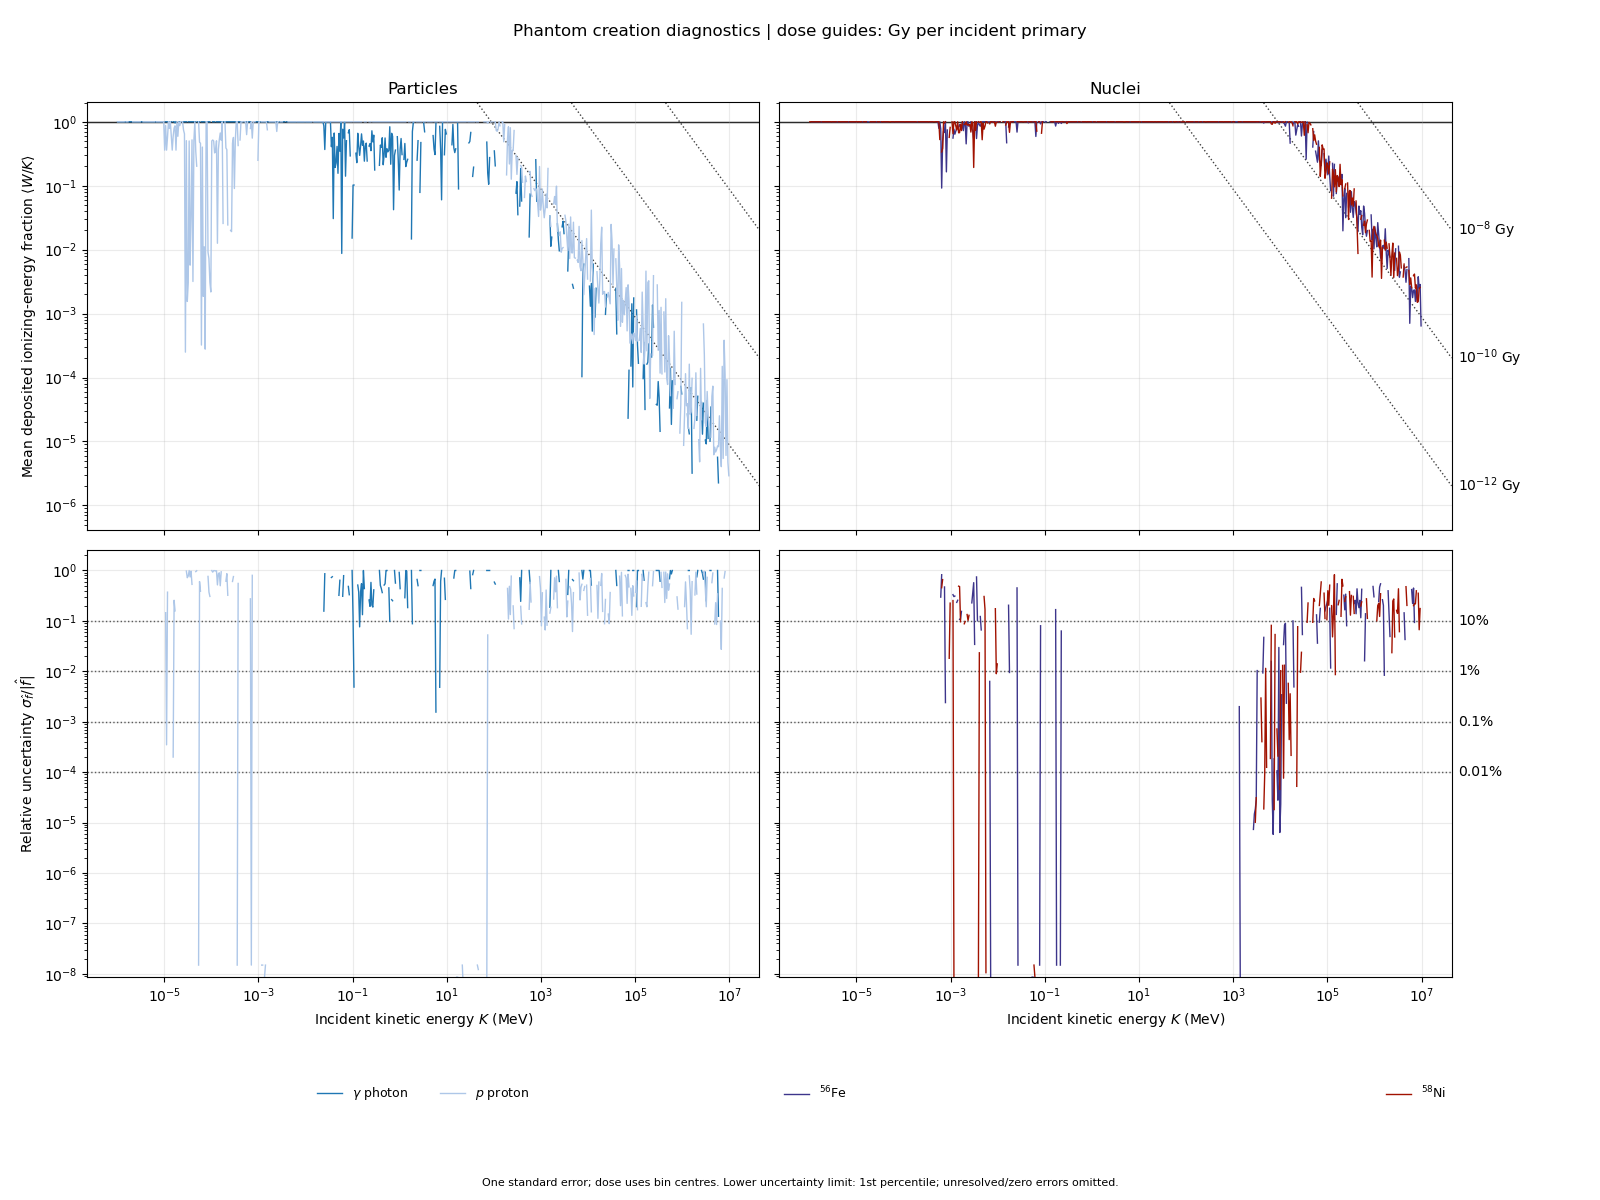

In [6]:
display(Image(filename=str(run_dir / "export" / "diagnostics.png")))

The second diagnostic shows both quality measures: relative response uncertainty and absolute dose uncertainty. Both are one standard error. Grey marks unresolved or zero estimated errors, not certified zero physical response.

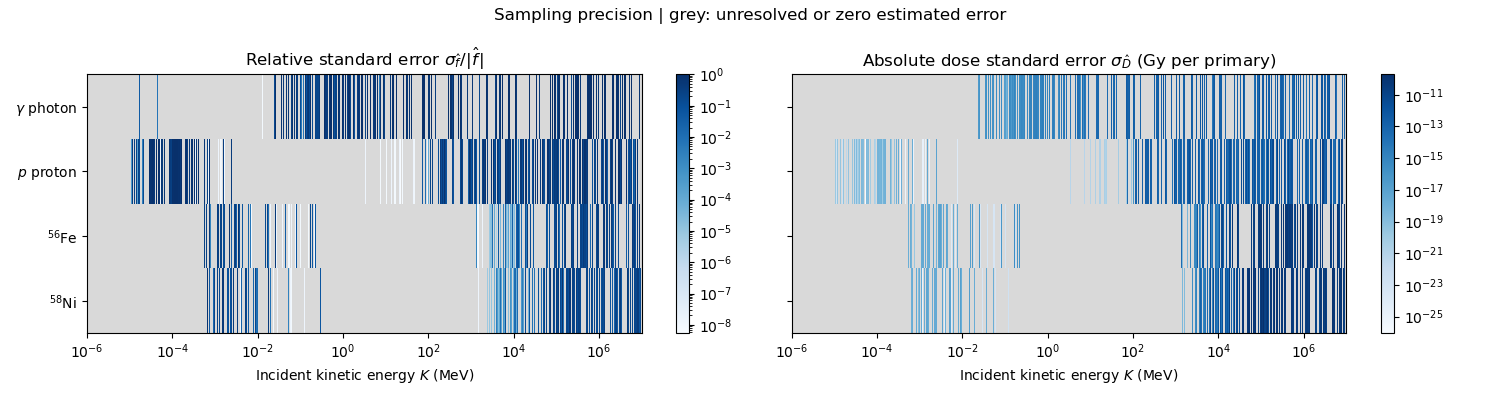

In [7]:
display(Image(filename=str(run_dir / "export" / "sampling-precision.png")))

## 7. Refine only if you want to

In the run directory, add a bounded adaptive batch:

```bash
atris-build-phantom . --adaptive --batches 5 --threads 1
```

The builder first covers species, then explores missing or unmeasured ranges. With matching-thread timings, it prefers predicted energy-precision improvement per second. Every fifth selection makes a coverage turn. Forecasts and observed timings remain in `batches.json`.

Counting is exported but does not drive priority or completion. The energy target combines relative tolerance with an absolute dose floor; see [refinement and precision](../running-atris/build-phantoms.md#refine-and-inspect). Zero observed deposits remain unresolved even with zero estimated variance.

After further batches, repeat the post-processing cells. To refresh from the terminal without transport:

```bash
atris-build-phantom . --postprocess-only
```

## 8. Inspect and use the exports

`export/` contains response/counting matrices, sampling arrays, metadata, diagnostics, and `sampling-state.json`. Pilot matrices may contain NaNs; those partial tables are not loadable by AtRIS. A fully populated table can still require more sampling, so inspect precision as well as coverage.

The regular `atris-plot` image combines counting efficiency and deposited fraction, with constant deposited-energy guides. Creation diagnostics stay with the builder, not atmospheric input plots.

Follow [phantom selection and staging](../running-atris/prepare-simulation.md#optionally-select-phantoms) to use verified tables in a prepared atmospheric run. The [spectrum-folding notebook](earth-spectrum-folding.ipynb) explains physical source rates.